# __Competición CNN 2026. Clasificación binaria.__

Para esta competición, nuestro grupo ha decidido clasificar las imagenes del dataset de cartas debido a si son figuras o no. Esto corresponde a las cartas con valor de carácter en vez de numérico.

Se pretende agrupar las cartas en dos grandes grupos dependiendo de si tienen valor numérico o si son representadas por un caracter (A, J, Q, K, Joker).

## Pasos previos.

Antes de poder empezar a crear código, se ha tenido que reorganizar el dataset original, que consitía de una carpeta por cada carta de cada palo, en dos únicas carpetas, a estas se les llama:

- face_cards: La carpeta que contiene todas las cartas con valores de carácter. En español a estas cartas se les llama figuras, pero para la baraja de poker la terminología es face cards o court cards.
- non_face_cards: La clase contraría, carpeta que contiene todas las cartas con valor numérico.

Estas divisiones se han tenido que hacer para las tres subdivisiones: test, train y validation.

## Instalación de librerías.

In [16]:
import os
import numpy as np
import matplotlib.pyplot as plt
import random
import torch
import torch.nn as nn
import cv2

## 1. Inclusión de datasets.

### 1.1. Descargar datasets.

En el caso de tener un token de kaggle configurado se puede descargar mediante los siguientes comandos de bash:

- kaggle datasets download -d cesarvidal/cards-dataset
- unzip -q cards-dataset.zip -d cards

### 1.2. Cargar datasets.

In [ ]:
import os
import cv2
import numpy as np

TRAIN_DIR = "cards/train"
TEST_DIR = "cards/test"
VAL_DIR = "cards/valid"

IMG_SIZE = (224, 224)

def load_directory_with_labels(path):

    images = []
    labels = []
    
    # os.walk baja por todas las subcarpetas automáticamente
    for root, subdirs, files in os.walk(path):
        for file in files:

            # Solo los .jpg, para que no se cuele nada raro.
            if file.lower().endswith('.jpg'):
                img_path = os.path.join(root, file)
                img = cv2.imread(img_path)  
                
                if img is not None:
                    
                    img = cv2.resize(img, IMG_SIZE)
                    images.append(img)

                    # --- ETIQUETAMOS.
                    if "face_cards" in root:
                        labels.append(1)

                    elif "non_face_cards" in root:
                        labels.append(0)
                        
    return np.array(images), np.array(labels)

print("Cargando training...")
X_train, y_train = load_directory_with_labels(TRAIN_DIR)

print("Cargando validación...")
X_val, y_val = load_directory_with_labels(VAL_DIR)

print("Cargando test...")
X_test, y_test = load_directory_with_labels(TEST_DIR)

print("\nTodo cargado con éxito.")
print(f"X_train shape: {X_train.shape} | y_train shape: {y_train.shape}")
print(f"X_val shape:   {X_val.shape}   | y_val shape:   {y_val.shape}")
print(f"X_test shape:  {X_test.shape}  | y_test shape:  {y_test.shape}")

Cargando training...
Cargando validación...
Cargando test...

Todo cargado con éxito.
X_train shape: (7619, 224, 224, 3) | y_train shape: (7619,)
X_val shape:   (265, 224, 224, 3)   | y_val shape:   (265,)
X_test shape:  (265, 224, 224, 3)  | y_test shape:  (265,)


### 1.1. Observar algún dato.

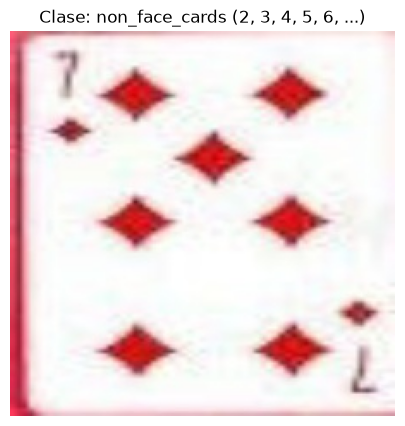

In [27]:
# Elegimos una carta aleatoria.
idx = random.randint(0, len(X_train) - 1)

imagen = X_train[idx]

etiqueta = y_train[idx]
nombre_clase = "face_cards (A, J, Q, K, Joker)" if etiqueta == 1 else "non_face_cards (2, 3, 4, 5, 6, ...)"

# Convertimos de RGB.
img_rgb = cv2.cvtColor(imagen, cv2.COLOR_BGR2RGB)

# Mostramos la imagen
plt.figure(figsize=(5, 5))
plt.imshow(img_rgb)
plt.title(f"Clase: {nombre_clase}")
plt.axis('off')
plt.show()

# 2. Preparación de los datos.

### 2.1. (Opcional): Data Augmentation

### 2.2 (Opcional): Normalización.

## 3. Montaje de la red.

### 3.1. Definición y justificación de capas y parámetros.

### 3.2. Estructura y capas.

## 4. Entrenamiento. 

## 5. Validación y test.

## 6. Métricas.

## 7. Conclusiones.